> **หมายเหตุ:** โน้ตบุ๊กนี้เป็นบันทึกการฝึกสอนแบบจำลองรุ่นแรก (v1) ที่เก็บไว้เป็นประวัติ ข้อความที่อ้างถึง `ai-service/main.py` (FastAPI) เป็นของโครงสร้างเดิมซึ่งถูกนำออกแล้ว ปัจจุบันระบบรัน AI บนอุปกรณ์ด้วย TensorFlow Lite (แอป) และ ONNX (เว็บ) ดู `ai-service/README.md` และ `training/README.md`


# 🌾 Rice AI — เทรนโมเดลจำแนกโรคใบข้าว (Google Colab)

โน้ตบุ๊กนี้ใช้เทรนโมเดลจำแนกภาพสำหรับระบบ **Rice AI** (4 คลาส: **โรคไหม้
(Rice Blast)**, **โรคขอบใบแห้ง (Bacterial Leaf Blight)**, **โรคใบสีส้ม
(Rice Tungro Virus)**, **ใบข้าวปกติ (Healthy)**) และส่งออกไฟล์โมเดลที่นำไป
ใส่ใน `ai-service/` (FastAPI service) ของโปรเจกต์ Rice AI หลักได้ทันที
แทนที่ classifier ปลอม (placeholder) ที่ใช้อยู่ตอนนี้

**Runtime ที่ต้องใช้:** ใน Colab ไปที่ `Runtime → Change runtime type → GPU`
(T4 ก็เพียงพอแล้ว)

## ขั้นตอนในโน้ตบุ๊กนี้
1. ดาวน์โหลด dataset โรคใบข้าว/ใบข้าวโพด (paddy) สาธารณะจาก Kaggle
2. กรองให้เหลือเฉพาะ 4 คลาสที่เราต้องการ
3. เทรนโมเดลแบบ transfer learning (EfficientNetB0)
4. Fine-tune ชั้นบนของโมเดล
5. ประเมินผลบน validation set (accuracy, confusion matrix, รายงานแยกคลาส)
6. Export เป็น `rice_disease_model.h5` + `class_indices.json` (และไฟล์
   `.tflite` แบบเผื่อไว้สำหรับใช้บนมือถือแบบ offline ในอนาคต)
7. บอกโค้ดที่ต้องนำไปวางใน `ai-service/main.py` เพื่อใช้โมเดลจริงแทน mock

## เรื่อง Dataset
เอกสารต้นฉบับของโปรเจกต์ไม่ได้แนบ dataset ที่มีป้ายกำกับ (labeled) มาให้
โน้ตบุ๊กนี้จึงใช้ dataset **"Paddy Doctor / Paddy Disease Classification"**
จาก Kaggle (Petchiammal et al., 2023 — เป็น dataset ของการแข่งขัน, ดาวน์โหลด
ด้วยคำสั่ง `kaggle competitions download -c paddy-disease-classification`)
ซึ่งเป็นหนึ่งใน dataset สาธารณะไม่กี่ตัวที่มีครบทั้ง 4 คลาสที่เราต้องการ
อยู่ในที่เดียวกัน มีป้ายกำกับสม่ำเสมอ และมีรูปมากกว่า 1,000 รูปต่อคลาส:

| โฟลเดอร์ใน dataset | แม็ปเป็นคลาสของเรา |
|---|---|
| `blast` | `BLAST` — โรคไหม้ |
| `bacterial_leaf_blight` | `BLB` — โรคขอบใบแห้ง |
| `tungro` | `TUNGRO` — โรคใบสีส้ม |
| `normal` | `HEALTHY` — ใบข้าวปกติ |

ใน dataset นี้ยังมีคลาสอื่นด้วย (brown_spot, hispa, dead_heart ฯลฯ) —
โน้ตบุ๊กนี้ **จะไม่ใช้คลาสเหล่านั้น** เพราะอยู่นอกขอบเขต 4 คลาสของเรา
ถ้าคุณมี dataset ของตัวเอง ให้ข้ามไปที่ **หัวข้อ 2B** แล้วตั้งค่า
`CLASS_MAP` ให้ชี้ไปที่ชื่อโฟลเดอร์ของคุณเอง

⚠️ **ก่อนจะเชื่อผลลัพธ์นี้ไปใช้งานจริง:** ตรวจสอบสัญญาอนุญาต (license)
ของ dataset ที่ใช้ว่าตรงกับวัตถุประสงค์การใช้งานของคุณหรือไม่ และควร
มองตัวเลข accuracy อย่างตรงไปตรงมา — ค่า accuracy บน validation set ที่มา
จาก dataset สะอาดๆ มักจะดูดีกว่าความแม่นยำจริงเมื่อใช้กับรูปสภาพแปลงนา
จริง (มือถือคนละรุ่น แสงต่างกัน พื้นหลังรก มุมถ่ายต่างกัน ระยะของโรค
ต่างกัน) ให้มองว่านี่คือจุดเริ่มต้นที่ดี ไม่ใช่ผลิตภัณฑ์ที่เสร็จสมบูรณ์
เหมือนที่เขียนไว้ใน `docs/ASSUMPTIONS_AND_TODOS.md` ของโปรเจกต์หลัก


## 1. ติดตั้งเครื่องมือที่ต้องใช้

In [ ]:
#@title ติดตั้ง/ตรวจสอบไลบรารีที่ต้องใช้
!pip install -q kaggle tensorflow scikit-learn seaborn

import os, json, shutil, pathlib, random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("มี GPU ให้ใช้หรือไม่:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.20.0
มี GPU ให้ใช้หรือไม่: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
#@title ตั้งค่า seed เพื่อให้ผลลัพธ์ทำซ้ำได้ (reproducibility)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


## 2A. ดาวน์โหลด dataset จาก Kaggle

ต้องมีบัญชี Kaggle (ฟรี) + API token:
1. ไปที่ https://www.kaggle.com/settings → **API → Create New Token**
   จะได้ไฟล์ `kaggle.json` มา
2. รันเซลล์ด้านล่าง แล้วอัปโหลดไฟล์นั้นเมื่อระบบถาม
3. ต้อง **เข้าร่วมการแข่งขัน (join competition)** ที่
   https://www.kaggle.com/c/paddy-disease-classification/rules ก่อน 1 ครั้ง
   (ฟรี แค่กด "I Understand and Accept") ไม่งั้น Kaggle จะบล็อกการ
   ดาวน์โหลดผ่าน API


In [ ]:
#@title อัปโหลด kaggle.json
from google.colab import files

if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("กรุณาอัปโหลดไฟล์ kaggle.json (ดาวน์โหลดจาก https://www.kaggle.com/settings):")
    uploaded = files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    shutil.move(list(uploaded.keys())[0], '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)
    print("ติดตั้ง kaggle.json เรียบร้อย")
else:
    print("มี kaggle.json อยู่แล้ว")


มี kaggle.json อยู่แล้ว


In [ ]:
#@title ดาวน์โหลด + แตกไฟล์ dataset Paddy Disease Classification
DATA_ROOT = '/content/paddy_raw'

if not os.path.exists(DATA_ROOT):
    os.makedirs(DATA_ROOT, exist_ok=True)
    get_ipython().system('kaggle competitions download -c paddy-disease-classification -p /content')
    get_ipython().system('unzip -q /content/paddy-disease-classification.zip -d ' + DATA_ROOT)

# ไฟล์ zip ของการแข่งขันจะแตกออกมาเป็น DATA_ROOT/train_images/<ชื่อคลาส>/*.jpg
TRAIN_IMAGES_DIR = os.path.join(DATA_ROOT, 'train_images')
print("คลาสทั้งหมดที่พบใน dataset ดิบ:", sorted(os.listdir(TRAIN_IMAGES_DIR)))


คลาสทั้งหมดที่พบใน dataset ดิบ: ['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'blast', 'brown_spot', 'dead_heart', 'downy_mildew', 'hispa', 'normal', 'tungro']


## 2B. ใช้ dataset ของตัวเองแทน

ถ้าคุณมีรูปที่มีป้ายกำกับเป็นของตัวเอง (เช่น เก็บจากเกษตรกรจริง หรือ
dataset สาธารณะตัวอื่น) ให้ข้ามหัวข้อ 2A แล้วทำตามนี้แทน:

1. อัปโหลด/mount โฟลเดอร์ที่มี 1 โฟลเดอร์ย่อยต่อ 1 คลาส (ตั้งชื่ออะไรก็ได้)
2. ตั้งค่า `TRAIN_IMAGES_DIR` ให้ชี้ไปที่โฟลเดอร์นั้น
3. แก้ `CLASS_MAP` ด้านล่างให้แต่ละชื่อโฟลเดอร์ของคุณแม็ปไปยัง 1 ใน 4
   รหัสคลาสมาตรฐาน: `BLAST`, `BLB`, `TUNGRO`, `HEALTHY` — ไม่จำเป็นต้องมี
   ครบทั้ง 4 คลาสก็ได้ แต่ `ai-service` คาดหวังว่าจะมีครบทั้ง 4 รหัสนี้
   ตามลำดับนี้ ถ้าคุณมีคลาสน้อยกว่านั้น ก็ต้องไปแก้ `CLASSES` ใน
   `ai-service/main.py` ให้ตรงกันด้วย

```python
# ตัวอย่างสำหรับ dataset ที่มีโครงสร้างต่างออกไป:
TRAIN_IMAGES_DIR = '/content/drive/MyDrive/my_rice_dataset'
CLASS_MAP = {
    'ชื่อโฟลเดอร์โรคไหม้ของคุณ': 'BLAST',
    'ชื่อโฟลเดอร์โรคขอบใบแห้งของคุณ': 'BLB',
    'ชื่อโฟลเดอร์โรคใบสีส้มของคุณ': 'TUNGRO',
    'ชื่อโฟลเดอร์ใบปกติของคุณ': 'HEALTHY',
}
```


In [ ]:
#@title แม็ปโฟลเดอร์ต้นทาง -> 4 คลาสมาตรฐานของเรา
# การแม็ปนี้ตรงกับชื่อโฟลเดอร์ของ Kaggle "paddy-disease-classification" ในหัวข้อ 2A
# ถ้าใช้หัวข้อ 2B (dataset ของตัวเอง) ให้แก้ตรงนี้
CLASS_MAP = {
    'blast': 'BLAST',
    'bacterial_leaf_blight': 'BLB',
    'tungro': 'TUNGRO',
    'normal': 'HEALTHY',
}

# ลำดับนี้ต้องตรงกับ CLASSES ใน ai-service/main.py — ลำดับ index ของ output
# โมเดลขึ้นอยู่กับลิสต์นี้ และ ai-service จะแม็ป index -> รหัสคลาส ตามลำดับนี้เป๊ะๆ
CANONICAL_CLASSES = ['BLAST', 'BLB', 'TUNGRO', 'HEALTHY']

assert set(CLASS_MAP.values()) <= set(CANONICAL_CLASSES)
print("การแม็ปถูกต้อง:", CLASS_MAP)


การแม็ปถูกต้อง: {'blast': 'BLAST', 'bacterial_leaf_blight': 'BLB', 'tungro': 'TUNGRO', 'normal': 'HEALTHY'}


In [ ]:
#@title สร้างโฟลเดอร์ dataset 4 คลาสที่สะอาด (คัดมาเฉพาะที่ต้องใช้)
CLEAN_ROOT = '/content/rice4'

if os.path.exists(CLEAN_ROOT):
    shutil.rmtree(CLEAN_ROOT)
os.makedirs(CLEAN_ROOT, exist_ok=True)

counts = {}
for src_name, target_class in CLASS_MAP.items():
    src_dir = os.path.join(TRAIN_IMAGES_DIR, src_name)
    dst_dir = os.path.join(CLEAN_ROOT, target_class)
    os.makedirs(dst_dir, exist_ok=True)
    if not os.path.isdir(src_dir):
        print(f"คำเตือน: ไม่พบโฟลเดอร์ต้นทาง ข้ามไป: {src_dir}")
        continue
    n = 0
    for fname in os.listdir(src_dir):
        # ใช้ symlink แทนการ copy จริง เพื่อประหยัดพื้นที่/เวลาใน Colab
        src_path = os.path.join(src_dir, fname)
        dst_path = os.path.join(dst_dir, fname)
        if not os.path.exists(dst_path):
            os.symlink(src_path, dst_path)
        n += 1
    counts[target_class] = n

print("จำนวนรูปในแต่ละคลาส:")
for c in CANONICAL_CLASSES:
    print(f"  {c}: {counts.get(c, 0)}")


จำนวนรูปในแต่ละคลาส:
  BLAST: 1738
  BLB: 479
  TUNGRO: 1088
  HEALTHY: 1764


## 3. ดูข้อมูลตัวอย่าง

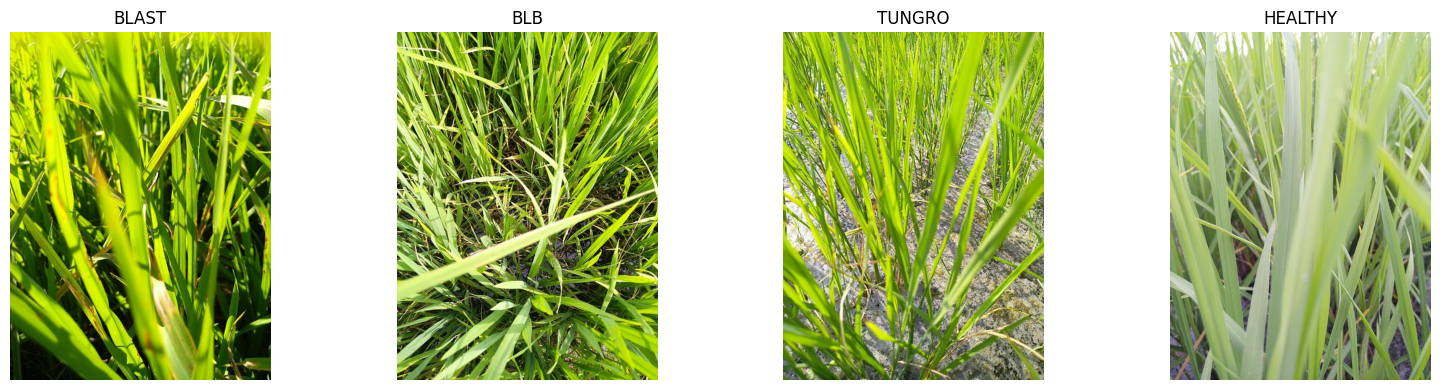

In [ ]:
#@title ดูตัวอย่างรูปจากแต่ละคลาส
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, len(CANONICAL_CLASSES), figsize=(16, 4))
for ax, cls in zip(axes, CANONICAL_CLASSES):
    cls_dir = os.path.join(CLEAN_ROOT, cls)
    files_in_dir = os.listdir(cls_dir)
    if not files_in_dir:
        ax.set_title(f"{cls} (ไม่มีรูป)")
        ax.axis('off')
        continue
    sample = random.choice(files_in_dir)
    img = Image.open(os.path.join(cls_dir, sample)).convert('RGB')
    ax.imshow(img)
    ax.set_title(cls)
    ax.axis('off')
plt.tight_layout()
plt.show()


## 4. สร้างชุดข้อมูล train/validation

กำหนด `class_names` แบบระบุตายตัว เพื่อให้ index ของ label (0,1,2,3) ตรงกับ
`CANONICAL_CLASSES` เป๊ะๆ — จุดนี้คือสิ่งที่ทำให้ลำดับ output ของโมเดลที่
export ออกไป เข้ากันได้กับ `ai-service/main.py`


In [ ]:
#@title ตั้งค่า dataset
IMG_SIZE = (224, 224)   # ขนาด input มาตรฐานของ EfficientNetB0
BATCH_SIZE = 32
VAL_SPLIT = 0.15


In [ ]:
#@title สร้าง tf.data pipeline
train_ds = tf.keras.utils.image_dataset_from_directory(
    CLEAN_ROOT,
    validation_split=VAL_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=CANONICAL_CLASSES,
    label_mode='categorical',
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    CLEAN_ROOT,
    validation_split=VAL_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=CANONICAL_CLASSES,
    label_mode='categorical',
)

print("class_names (ลำดับนี้สำคัญมาก!):", train_ds.class_names)
assert train_ds.class_names == CANONICAL_CLASSES

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)


Found 5069 files belonging to 4 classes.
Using 4309 files for training.
Found 5069 files belonging to 4 classes.
Using 760 files for validation.
class_names (ลำดับนี้สำคัญมาก!): ['BLAST', 'BLB', 'TUNGRO', 'HEALTHY']


In [ ]:
#@title คำนวณ class weight (จัดการปัญหาจำนวนรูปแต่ละคลาสไม่เท่ากัน)
import collections

class_counts = collections.Counter()
for cls in CANONICAL_CLASSES:
    class_counts[cls] = len(os.listdir(os.path.join(CLEAN_ROOT, cls)))

total = sum(class_counts.values())
n_classes = len(CANONICAL_CLASSES)
class_weight = {
    i: total / (n_classes * class_counts[cls])
    for i, cls in enumerate(CANONICAL_CLASSES)
}
print("class_weight:", class_weight)


class_weight: {0: 0.7291426927502876, 1: 2.645615866388309, 2: 1.1647518382352942, 3: 0.7183956916099773}


## 5. Data Augmentation

รูปใบข้าวในสภาพแปลงนาจริงมีความหลากหลายทั้งมุมถ่าย แสง และการจัดเฟรม —
จึงต้อง augment ให้ครอบคลุมความหลากหลายนี้ แต่ต้องระวังไม่ให้บิดเบือน
สี/พื้นผิวที่เป็นตัวบ่งชี้โรคมากเกินไป (โดยเฉพาะการสุ่มเปลี่ยน hue/
saturation เพราะสีของรอยโรคคือข้อมูลสำคัญในการวินิจฉัย)


In [ ]:
#@title ชั้น augmentation (ใช้เฉพาะตอนเทรนเท่านั้น)
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
    layers.RandomBrightness(0.1),
], name="data_augmentation")


## 6. สร้างโมเดล — Transfer Learning ด้วย EfficientNetB0

เทรน 2 เฟส:
- **เฟส 1:** ล็อก (freeze) โมเดลฐานที่ pretrain มาแล้ว เทรนเฉพาะส่วนหัว
  (classification head) ที่เพิ่มเข้ามาใหม่
- **เฟส 2 (fine-tune):** ปลดล็อกชั้นบนสุดของโมเดลฐาน แล้วเทรนทั้งหมด
  พร้อมกันด้วย learning rate ที่ต่ำลงมาก


In [ ]:
#@title โครงสร้างโมเดล
NUM_CLASSES = len(CANONICAL_CLASSES)

base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=IMG_SIZE + (3,),
    pooling="avg",
)
base_model.trainable = False  # เฟส 1: ล็อกโมเดลฐานไว้ก่อน

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = keras.applications.efficientnet.preprocess_input(x)
x = base_model(x, training=False)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
model = keras.Model(inputs, outputs, name="rice_disease_classifier")

model.summary()


Model: "rice_disease_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
#@title Compile โมเดล (เฟส 1)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)


In [ ]:
#@title Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    keras.callbacks.ModelCheckpoint("/content/best_phase1.keras", monitor="val_accuracy", save_best_only=True),
]


In [ ]:
#@title เทรน — เฟส 1 (ล็อกโมเดลฐาน)
EPOCHS_PHASE1 = 15

history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    class_weight=class_weight,
    callbacks=callbacks,
)


Epoch 1/15
135/135 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - accuracy: 0.5008 - auc: 0.7515 - loss: 1.1801 - val_accuracy: 0.4895 - val_auc: 0.7715 - val_loss: 1.1123 - learning_rate: 0.0010
Epoch 2/15
135/135 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.5997 - auc: 0.8356 - loss: 1.0090 - val_accuracy: 0.4803 - val_auc: 0.7852 - val_loss: 1.0848 - learning_rate: 0.0010
Epoch 3/15
135/135 ━━━━━━━━━━━━━━━━━━━━ 12s 92ms/step - accuracy: 0.6303 - auc: 0.8591 - loss: 0.9481 - val_accuracy: 0.5474 - val_auc: 0.8200 - val_loss: 0.9981 - learning_rate: 0.0010
Epoch 4/15
135/135 ━━━━━━━━━━━━━━━━━━━━ 12s 93ms/step - accuracy: 0.6549 - auc: 0.8748 - loss: 0.9035 - val_accuracy: 0.6447 - val_auc: 0.8737 - val_loss: 0.8636 - learning_rate: 0.0010
Epoch 5/15
135/135 ━━━━━━━━━━━━━━━━━━━━ 12s 92ms/step - accuracy: 0.6718 - auc: 0.8840 - loss: 0.8781 - val_accuracy: 0.5934 - val_auc: 0.8530 - val_loss: 0.9152 - learning_rate: 0.0010
Epoch 6/15
135/135 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.6

## 7. Fine-tune (เฟส 2)

ปลดล็อกชั้นบนสุดประมาณ 20% ของโมเดลฐาน แล้วเทรนต่อด้วย learning rate ที่
ต่ำลงมาก เพื่อปรับ feature ที่เรียนรู้จาก ImageNet ให้เข้ากับลักษณะเฉพาะ
ของใบข้าว โดยไม่ทำลาย weight เดิมที่ pretrain มา


In [ ]:
#@title ปลดล็อกชั้นบนของโมเดลฐาน
base_model.trainable = True

# คงล็อกชั้นแรกๆ ไว้ (feature ทั่วไป) fine-tune เฉพาะชั้นหลังๆ
fine_tune_at = int(len(base_model.layers) * 0.8)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # learning rate ต่ำมากสำหรับ fine-tune
    loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)

model.summary()


Model: "rice_disease_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 2,310,420 (8.81 MB)

 Non-trainable params: 1,744,275 (6.65 MB)

In [ ]:
#@title เทรน — เฟส 2 (fine-tuning)
EPOCHS_PHASE2 = 10
total_epochs = EPOCHS_PHASE1 + EPOCHS_PHASE2

callbacks_ft = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7),
    keras.callbacks.ModelCheckpoint("/content/best_finetuned.keras", monitor="val_accuracy", save_best_only=True),
]

history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=history_1.epoch[-1] + 1,
    class_weight=class_weight,
    callbacks=callbacks_ft,
)


Epoch 12/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 36s 144ms/step - accuracy: 0.5802 - auc: 0.8104 - loss: 1.0770 - val_accuracy: 0.6842 - val_auc: 0.8907 - val_loss: 0.7994 - learning_rate: 1.0000e-05
Epoch 13/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 16s 116ms/step - accuracy: 0.6254 - auc: 0.8486 - loss: 0.9675 - val_accuracy: 0.6671 - val_auc: 0.8829 - val_loss: 0.8266 - learning_rate: 1.0000e-05
Epoch 14/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 16s 117ms/step - accuracy: 0.6595 - auc: 0.8715 - loss: 0.9146 - val_accuracy: 0.6618 - val_auc: 0.8832 - val_loss: 0.8257 - learning_rate: 1.0000e-05
Epoch 15/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 15s 114ms/step - accuracy: 0.6751 - auc: 0.8799 - loss: 0.8736 - val_accuracy: 0.6724 - val_auc: 0.8879 - val_loss: 0.8096 - learning_rate: 5.0000e-06
Epoch 16/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 16s 119ms/step - accuracy: 0.6846 - auc: 0.8860 - loss: 0.8571 - val_accuracy: 0.6895 - val_auc: 0.8929 - val_loss: 0.7923 - learning_rate: 5.0000e-06
Epoch 17/25
135/135 ━━━━━━━━━━━━━━━━━━━━

## 8. กราฟการเทรน

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3636 (\N{THAI CHARACTER SARA I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


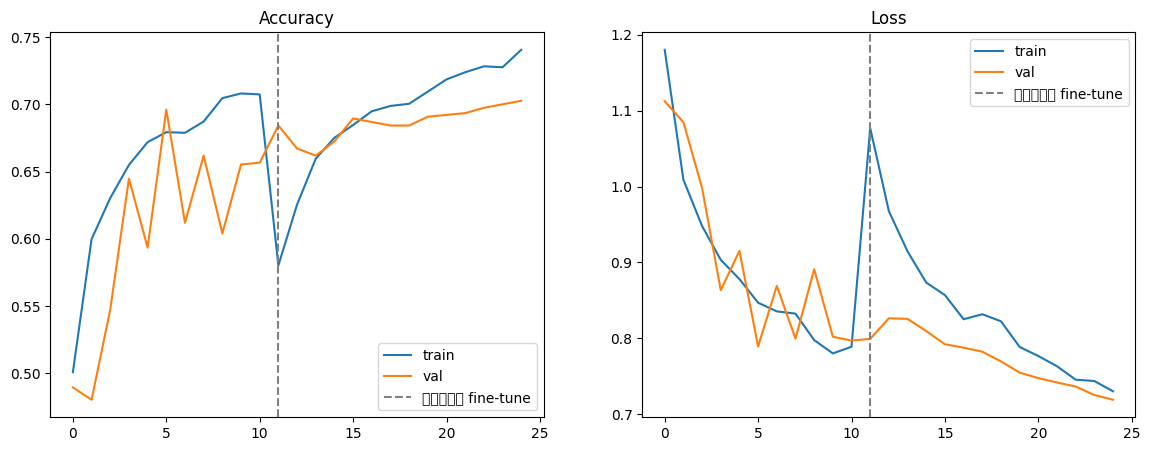

In [ ]:
#@title พล็อตกราฟ accuracy & loss ทั้ง 2 เฟส
def combine(hist_list, key):
    out = []
    for h in hist_list:
        out += h.history.get(key, [])
    return out

acc = combine([history_1, history_2], "accuracy")
val_acc = combine([history_1, history_2], "val_accuracy")
loss = combine([history_1, history_2], "loss")
val_loss = combine([history_1, history_2], "val_loss")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(acc, label="train")
axes[0].plot(val_acc, label="val")
axes[0].axvline(len(history_1.history["accuracy"]), color="gray", linestyle="--", label="เริ่ม fine-tune")
axes[0].set_title("Accuracy")
axes[0].legend()

axes[1].plot(loss, label="train")
axes[1].plot(val_loss, label="val")
axes[1].axvline(len(history_1.history["loss"]), color="gray", linestyle="--", label="เริ่ม fine-tune")
axes[1].set_title("Loss")
axes[1].legend()
plt.show()


## 9. ประเมินผลโมเดล

ดู confusion matrix + รายงาน precision/recall/F1 แยกตามคลาส บน
validation set ที่กันไว้ **อ่านผลลัพธ์อย่างตรงไปตรงมา** — validation set
ที่มาจาก dataset เดียวกับตอนเทรน มักจะให้ผลดีกว่าความแม่นยำจริงเมื่อใช้
กับรูปที่เกษตรกรถ่ายเอง (ดูคำเตือนในหัวข้อ 0)


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, 

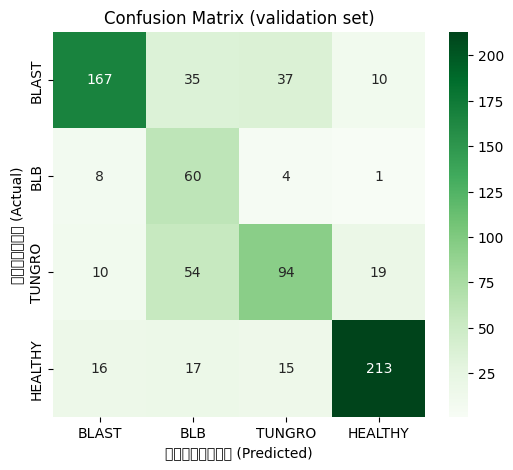

              precision    recall  f1-score   support

       BLAST      0.831     0.671     0.742       249
         BLB      0.361     0.822     0.502        73
      TUNGRO      0.627     0.531     0.575       177
     HEALTHY      0.877     0.816     0.845       261

    accuracy                          0.703       760
   macro avg      0.674     0.710     0.666       760
weighted avg      0.754     0.703     0.716       760



In [ ]:
#@title Confusion matrix + รายงานผลแยกคลาส
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = []
y_pred = []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=CANONICAL_CLASSES, yticklabels=CANONICAL_CLASSES)
plt.xlabel("ทำนายได้ (Predicted)")
plt.ylabel("ค่าจริง (Actual)")
plt.title("Confusion Matrix (validation set)")
plt.show()

print(classification_report(y_true, y_pred, target_names=CANONICAL_CLASSES, digits=3))


## 10. ส่งออกโมเดล (Export)

จะได้ไฟล์:
- `rice_disease_model.h5` — นำไปวางไว้ที่ `ai-service/model/` ในโปรเจกต์
  Rice AI หลัก (ตรงกับค่าเริ่มต้นของ `MODEL_PATH` ใน `ai-service/main.py`)
- `class_indices.json` — บันทึกลำดับคลาสที่ใช้จริง เพื่อไม่ให้
  `ai-service` ต้องเดาเอง
- (ถ้าต้องการ) `rice_disease_model.tflite` — เวอร์ชัน quantized สำหรับ
  ใช้ inference บนอุปกรณ์โดยตรง (on-device) ในแอพมือถือ Flutter ในอนาคต


In [ ]:
#@title บันทึกโมเดล Keras + ไฟล์แม็ปลำดับคลาส
EXPORT_DIR = '/content/export'
os.makedirs(EXPORT_DIR, exist_ok=True)

model.save(os.path.join(EXPORT_DIR, 'rice_disease_model.keras'))

with open(os.path.join(EXPORT_DIR, 'class_indices.json'), 'w') as f:
    json.dump({i: c for i, c in enumerate(CANONICAL_CLASSES)}, f, indent=2, ensure_ascii=False)

print("บันทึกไฟล์ไว้ที่:", EXPORT_DIR)
print(os.listdir(EXPORT_DIR))

บันทึกไฟล์ไว้ที่: /content/export
['rice_disease_model.keras', 'class_indices.json', 'rice_disease_model.h5']


In [ ]:
#@title (ถ้าต้องการ) แปลงเป็น TFLite ไว้ใช้ on-device/มือถือในอนาคต
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_path = os.path.join(EXPORT_DIR, 'rice_disease_model.tflite')
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

print(f"บันทึกโมเดล TFLite แล้ว: {tflite_path} ({os.path.getsize(tflite_path) / 1e6:.1f} MB)")


Saved artifact at '/tmp/tmp9unkmacd'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_489')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  136057846631888: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136057846632656: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136053949424144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136053949423952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136053949424720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136053949425680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136053949426256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136053949425104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136053949424912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136053949426064: TensorSpec(shape=(), dtype=tf.resource, name=

In [ ]:
#@title ดาวน์โหลดโฟลเดอร์ export ทั้งหมดเป็นไฟล์ zip
import shutil as _shutil
zip_path = '/content/rice_disease_model_export'
_shutil.make_archive(zip_path, 'zip', EXPORT_DIR)

from google.colab import files
files.download(zip_path + '.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**อีกทางเลือกหนึ่ง:** บันทึกลง Google Drive โดยตรงแทนการดาวน์โหลด:

```python
from google.colab import drive
drive.mount('/content/drive')
shutil.copytree(EXPORT_DIR, '/content/drive/MyDrive/rice_ai_model_export')
```


## 11. นำไปเชื่อมกับ `ai-service`

ในโปรเจกต์ Rice AI หลัก:

1. คัดลอกไฟล์ `rice_disease_model.h5` ไปไว้ที่ `ai-service/model/`
   (path ที่ `ai-service/main.py` รอไว้อยู่แล้วผ่านตัวแปร `MODEL_PATH`)
2. เอาคอมเมนต์ (`#`) หน้าบรรทัด `tensorflow`, `pillow`, `numpy` ใน
   `ai-service/requirements.txt` ออก แล้วรัน
   `pip install -r requirements.txt`
3. แทนที่ฟังก์ชัน `predict_with_real_model` ใน `ai-service/main.py` ด้วย
   โค้ดด้านล่างนี้ (จะถอดรหัสไฟล์ภาพ → ปรับขนาด → ทำนาย → แม็ปกลับเป็น
   รหัสคลาสโดยใช้ `class_indices.json`)

```python
import json
import numpy as np
from PIL import Image
import io

with open(os.path.join(os.path.dirname(MODEL_PATH), "class_indices.json")) as f:
    CLASS_INDEX_MAP = {int(k): v for k, v in json.load(f).items()}

def predict_with_real_model(image_bytes: bytes):
    img = Image.open(io.BytesIO(image_bytes)).convert("RGB").resize((224, 224))
    arr = np.expand_dims(np.array(img), axis=0).astype("float32")
    # หมายเหตุ: ไม่ต้อง preprocess เพิ่มเองตรงนี้ — ต้องตรงกับหัวข้อ 6
    # ด้านบน ซึ่ง preprocess_input ของ EfficientNet ถูกฝังอยู่ใน graph
    # ของโมเดลที่ export ออกไปแล้ว (ผ่านชั้น augmentation/preprocessing)
    preds = _model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(preds))
    confidence = round(float(preds[idx]) * 100, 2)
    return CLASS_INDEX_MAP[idx], confidence
```

4. รีสตาร์ทเซอร์วิส — `/health` ควรรายงาน
   `model_status: trained_model_loaded` และ `ai_source` ในผลการวินิจฉัย
   จะขึ้นเป็น `"ai-service"` (โมเดลจริง) แทนที่จะเป็นค่า mock สำรอง


## 12. ข้อจำกัดที่ต้องรู้ตรงๆ (อ่านก่อนนำไปใช้งานจริง)

- **ความแม่นยำจาก validation ≠ ความแม่นยำในโลกจริง** dataset นี้เก็บมา
  ในสภาพที่ค่อนข้างสม่ำเสมอ แต่รูปที่เกษตรกรถ่ายด้วยมือถือในแปลงนาจริง
  จะหลากหลายกว่ามาก (ภาพเบลอ แสงสะท้อน ระยะห่างไม่เท่ากัน พื้นหลังปน
  หลายอย่าง มีหลายใบในรูปเดียว พันธุ์ข้าว/ระยะการเจริญเติบโตต่างกัน)
  คาดว่าความแม่นยำจริงจะต่ำกว่าตัวเลขข้างต้น — ควรทดสอบกับรูปภาคสนามของ
  ตัวเองก่อนนำไปใช้งานจริง
- **ปัญหาจำนวนรูปแต่ละคลาสไม่เท่ากัน** ได้รับการแก้ไขบางส่วนด้วย
  `class_weight` เท่านั้น ถ้าคลาสไหนมีรูปน้อยกว่ามากๆ ควรเก็บรูปเพิ่ม
  ดีกว่าพึ่งการถ่วงน้ำหนักอย่างเดียว
- **นี่ไม่ใช่สิ่งทดแทน dataset ที่มีป้ายกำกับที่เอกสารต้นฉบับใช้ทำ
  เป้าหมาย 97.4%** — dataset และ weight ชุดนั้นไม่เคยถูกแนบมาให้ ดังนั้น
  โน้ตบุ๊กนี้ไม่สามารถทำซ้ำตัวเลขนั้นได้ ให้มองว่า 97.4% เป็นเป้าหมายที่
  ต้องพัฒนาไปให้ถึงด้วยข้อมูลที่มากขึ้น/ดีขึ้น ไม่ใช่ผลลัพธ์ที่รับประกัน
  จาก pipeline นี้
- ก่อนนำโมเดลนี้ไปใช้ประกอบการตัดสินใจใช้สารเคมี/ยาฆ่าแมลงจริง ควรให้
  นักวิชาการเกษตรตรวจสอบกรณีที่โมเดลทำนายผิด (เริ่มดูได้จาก confusion
  matrix ในหัวข้อ 9)
